## Loading and inspecting the data

We want to import the review data and verify the fields needed for a recommendation model. Each row represents one user rating a movie, `user_id` identifies the person and `movie_id` identifies the movie. We check for duplicates to make sure the same user movie rating isn't counted repeatedly.

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# Load the Letterboxd reviews dataset
csv_path = Path("../reviews_filtered.csv")

if not csv_path.exists():
    csv_path = Path("reviews_filtered.csv")

data = pd.read_csv(csv_path)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# Load the Letterboxd reviews dataset
csv_path = Path("../reviews_filtered.csv")

if not csv_path.exists():
    csv_path = Path("reviews_filtered.csv")

data = pd.read_csv(csv_path)

print("Dataset shape:", data.shape)
print(data.head())
print("Duplicate user-movie pairs:",
      data.duplicated(["user_id", "movie_id"]).sum())


print("Dataset shape:", data.shape)
print(data.head())
print("Duplicate user-movie pairs:",
      data.duplicated(["user_id", "movie_id"]).sum())


Dataset shape: (855434, 6)
   Unnamed: 0  movie_id                       name  count_  user_id  rating
0           0     34222  slumber-party-massacre-ii      32   438333       7
1           1     34222  slumber-party-massacre-ii      32   437213       8
2           2     34222  slumber-party-massacre-ii      32   434710       7
3           3     34222  slumber-party-massacre-ii      32   423063       5
4           4     34222  slumber-party-massacre-ii      32   244269       9
Duplicate user-movie pairs: 0
Dataset shape: (855434, 6)
   Unnamed: 0  movie_id                       name  count_  user_id  rating
0           0     34222  slumber-party-massacre-ii      32   438333       7
1           1     34222  slumber-party-massacre-ii      32   437213       8
2           2     34222  slumber-party-massacre-ii      32   434710       7
3           3     34222  slumber-party-massacre-ii      32   423063       5
4           4     34222  slumber-party-massacre-ii      32   244269       9
Dupl

From this output, we can say that the dataset has 855,434 rows and 6 colummns, and there were no duplicate-pairs. This means the data is properly prepared for a basic SVD prediction experiment. This doesn't mean we have perfect data for all other experiementations we might want to implement, that should also be checked.

In [7]:

reader = Reader(rating_scale=(1, 10))

dataset = Dataset.load_from_df(
    data[["user_id", "movie_id", "rating"]],
    reader
)

# Split ratings into training and testing sets
trainset, testset = train_test_split(
    dataset,
    test_size=0.2,
    random_state=42
)

# Train baseline SVD
model = SVD(random_state=42)
model.fit(trainset)

# Predict ratings in the test set
predictions = model.test(testset)

accuracy.rmse(predictions)
accuracy.mae(predictions)


RMSE: 1.5286
MAE:  1.1569


np.float64(1.1569329261872399)

Here, the goal was to measure how well the existing model predicts ratings it hasn't seen before. Using Suprise's `Reader ` for the 1-10 rating scale and then split the data into a testing and training set. After we use performance metrics like mean absolute error and root mean squared error to see how well the model performed.

For MAE we achieved a result of 1.1569 and a RMSE of 1.5286, this means on the held-out reviews the predictions differ from the real user ratings by about 1.157 points on average. Our RMSE indicates  that some larger misses have a meaningful effect on the score. 

In [8]:

# Convert predictions into a DataFrame
results = pd.DataFrame([
    {
        "user_id": p.uid,
        "movie_id": p.iid,
        "actual": p.r_ui,
        "predicted": p.est
    }
    for p in predictions
])

# Calculate absolute prediction error
results["absolute_error"] = abs(
    results["actual"] - results["predicted"]
)

# Attach movie names so that's its easier to interpret the results
movie_names = (
    data.drop_duplicates("movie_id")
    .set_index("movie_id")["name"]
)

results["movie_name"] = results["movie_id"].map(movie_names)

# Compute mean absolute error for each movie
movie_errors = (
    results.groupby(["movie_id", "movie_name"])
    .agg(
        num_predictions=("absolute_error", "size"),
        mae=("absolute_error", "mean")
    )
    .reset_index()
)
#we only want movies with at least 10 ratings to minimize noise.
high_error_movies = (
    movie_errors[movie_errors["num_predictions"] >= 10]
    .sort_values("mae", ascending=False)
)

display(high_error_movies.head(10))


,movie_id,movie_name,num_predictions,mae
505,40988,the-room,21,3.460560
5398,845043,dicks-the-musical,27,2.668268
4468,564087,miracle-in-cell-no-7-2019-1,10,2.659167
2594,141866,fateful-findings,10,2.549875
5254,790798,dave-chappelle-the-closer,14,2.540340
295,28566,starstruck-2010,12,2.427901
3793,425735,twisted-pair,11,2.422592
2694,170651,men-women-children,10,2.397841
628,43713,high-school-musical-2,22,2.390264
2487,110138,upstream-color,15,2.294173


In this section we calculate the `absolute_error` and group predictions by movie to compute each movie's mean absolute error to help us understand the model performance further. In our results we see that some movies have larger MAE than the overall test-set value of 1.1569. An example is how the model misses ratings for `the-room` by 3.4606 points on average across 21 test predictions. We don't know if these movies have unusual user opinions, rating distributions, or other characteristics that can give us more insight. 

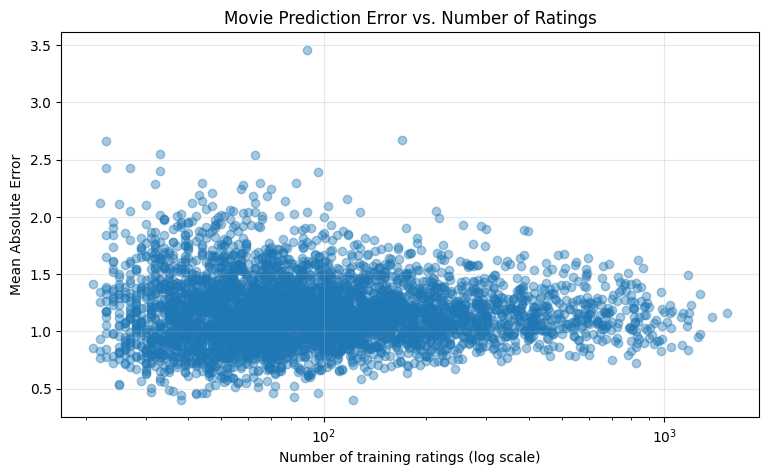

Spearman correlation: 0.0017512726829349615


In [9]:

# Count training ratings per movie
train_counts = {
    trainset.to_raw_iid(inner_id): len(movie_ratings)
    for inner_id, movie_ratings in trainset.ir.items()
}

movie_errors["train_rating_count"] = (
    movie_errors["movie_id"]
    .map(train_counts)
    .fillna(0)
    .astype(int)
)

plot_data = movie_errors[
    (movie_errors["num_predictions"] >= 10) &
    (movie_errors["train_rating_count"] > 0)
]

plt.figure(figsize=(9, 5))

plt.scatter(
    plot_data["train_rating_count"],
    plot_data["mae"],
    alpha=0.4
)

plt.xscale("log")
plt.xlabel("Number of training ratings (log scale)")
plt.ylabel("Mean Absolute Error")
plt.title("Movie Prediction Error vs. Number of Ratings")
plt.grid(alpha=0.3)
plt.show()

print(
    "Spearman correlation:",
    plot_data["train_rating_count"].corr(
        plot_data["mae"], method="spearman"
    )
)


Here we tested if movies with fewer known ratings are harder for SVD to predict. For each movie, we counted how many ratings are in training and compare it with the movie's held-out MAE. Then we generated a scatterplot to represent the movies, each dots represents a movie. The scatterplot uses a logarithmic x-axis since some movies have far more ratings than others. Then we calculate the spearman correlation to measure whether the two quantities tend to increase or decrease together in a monotonic way.

Our results gave us a output of 0.00175 for the spearman correlation, this means there is no linear relationship in the scatterplot. We also saw that within the movies with at least 10 held-out ratings, having more training ratings is not strongly associated with lower or higher MAE's. It seems that the higher errors appear more frequently in the lower-count region.

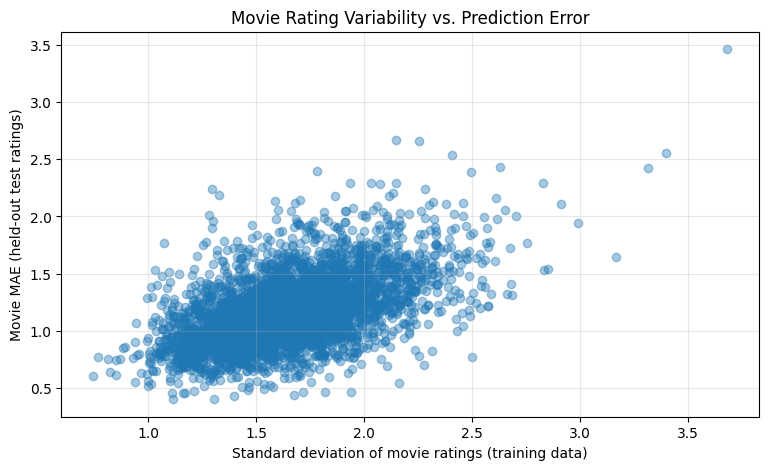

Movies analyzed: 4472
Spearman correlation: 0.5221218624666285


,movie_name,num_predictions,train_rating_count,rating_std,mae
505,the-room,21,89,3.680762,3.460560
5398,dicks-the-musical,27,170,2.148474,2.668268
4468,miracle-in-cell-no-7-2019-1,10,23,2.253675,2.659167
2594,fateful-findings,10,33,3.395630,2.549875
5254,dave-chappelle-the-closer,14,63,2.406575,2.540340
295,starstruck-2010,12,27,2.631174,2.427901
3793,twisted-pair,11,23,3.314837,2.422592
2694,men-women-children,10,33,1.779513,2.397841
628,high-school-musical-2,22,96,2.494533,2.390264
2487,upstream-color,15,65,2.030063,2.294173


In [ ]:
# Rebuild a simple table of ratings used to train the model.
train_ratings = pd.DataFrame([
    {"movie_id": trainset.to_raw_iid(inner_iid), "rating": rating}
    for _, inner_iid, rating in trainset.all_ratings()
])

movie_rating_stats = (
    train_ratings.groupby("movie_id")["rating"]
    .agg(rating_std="std", train_mean_rating="mean")
    .reset_index()
)


variability_data = movie_errors.merge(
    movie_rating_stats,
    on="movie_id",
    how="inner"
)

# Exclude movies with too few training or test ratings
variability_data = variability_data[
    (variability_data["num_predictions"] >= 10) &
    (variability_data["train_rating_count"] >= 10)
].dropna(subset=["rating_std", "mae"])

plt.figure(figsize=(9, 5))
plt.scatter(
    variability_data["rating_std"],
    variability_data["mae"],
    alpha=0.4
)
plt.xlabel("Standard deviation of movie ratings (training data)")
plt.ylabel("Movie MAE (held-out test ratings)")
plt.title("Movie Rating Variability vs. Prediction Error")
plt.grid(alpha=0.3)
plt.show()

std_mae_correlation = variability_data["rating_std"].corr(
    variability_data["mae"], method="spearman"
)
print("Movies analyzed:", len(variability_data))
print("Spearman correlation:", std_mae_correlation)

# See wether the hardest to perdict movies also have high rating variability
display(
    variability_data.sort_values("mae", ascending=False)[
        ["movie_name", "num_predictions", "train_rating_count", "rating_std", "mae"]
    ].head(10)
)

Now we test if movies with reviewers who have a tenency to give varying scores (so larger standard deviation) might be harder to predict than movies with consisitent ratings, This helps us understand why SVD reccomendation model makes bigger mistakes for certain movies.

Our new results show a interesting observation that the rating disagreement has a much stronger relationship with prediction error than the number of reviews a movie has. We found a Spearman correlation of 0.5221 between the standard deviation of movie ratings and prediction MAE. This also indicates a moderate positive relationship, so movies with more varied ratings tend to have higher prediction errors.

,actual,num_predictions,mae
0,1.0,3008,2.720065
1,2.0,6248,2.280581
2,3.0,6036,1.791475
3,4.0,14025,1.435633
4,5.0,15622,1.108270
5,6.0,29898,0.930410
6,7.0,30180,0.841078
7,8.0,35018,0.913747
8,9.0,16389,1.137172
9,10.0,14663,1.596389


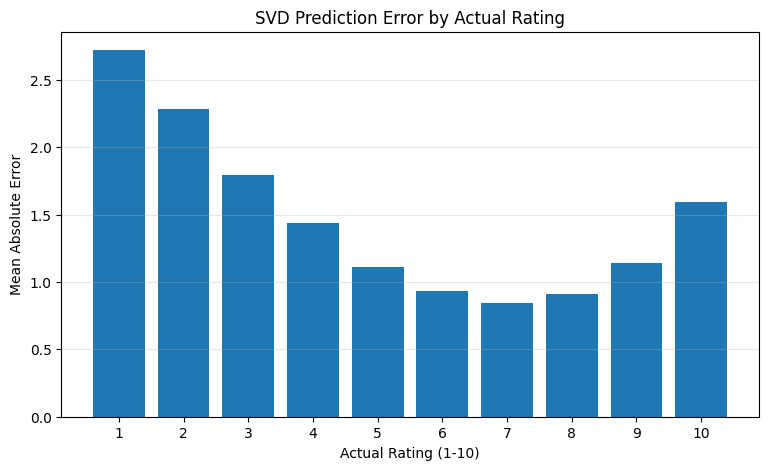

In [ ]:

# calculate prediction errors for each actual rating value
rating_errors = (
    results.groupby("actual")
    .agg(
        num_predictions=("absolute_error", "size"),
        mae=("absolute_error", "mean")
    )
    .reset_index()
    .sort_values("actual")
)

display(rating_errors)

# plot MAE 
plt.figure(figsize=(9, 5))

plt.bar(
    rating_errors["actual"].astype(int).astype(str),
    rating_errors["mae"]
)

plt.xlabel("Actual Rating (1-10)")
plt.ylabel("Mean Absolute Error")
plt.title("SVD Prediction Error by Actual Rating")
plt.grid(axis="y", alpha=0.3)

plt.show()


Now we want to investigate if the SVD model performs differently depending on the actual rating a user gives a movie. Our results show that SVD has a higher prediction error for extreme ratings (specifically the lower ratings). For example, ratings of 1 had the highest MAE of 2.72 while rating of 7 had the lowest MAE of 0.84. Ratings 7 and 8 were amongs the most common ratings in the test set and they had relatively low prediction errors. These finidngs are relevant to the proposed percentile-based rating transformation because the distribution is the rating values is not uniform. 